In [7]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import cv2

In [8]:
# Load VGG16 pre-trained on ImageNet, including its 1000-class classifier.
# (A new, untrained object/background head can't detect anything without training data.)
model = VGG16(weights='imagenet', include_top=True, input_shape=(224, 224, 3))

# Load and preprocess an example image for object detection
def preprocess_image(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (224, 224))
    img = np.expand_dims(img, axis=0)
    img = img / 255.0
    return img

def selective_search_regions(img, max_proposals=2000):
    # Selective search is slow on large images, so run it on a downscaled copy
    scale = min(1.0, 400 / max(img.shape[:2]))
    small = cv2.resize(img, None, fx=scale, fy=scale) if scale < 1 else img

    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(small)
    ss.switchToSelectiveSearchFast()
    rects = ss.process()[:max_proposals]  # limiting proposals for efficiency
    # Map boxes back to the original image size
    return (rects / scale).astype(int)

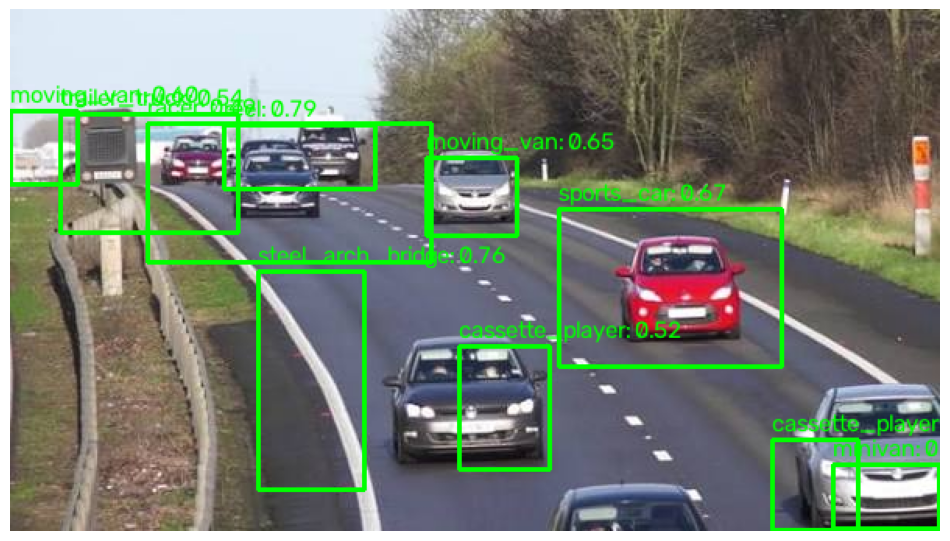

In [9]:
import matplotlib.pyplot as plt

img_path = 'images.jpeg'  # replace with path to your image
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError(f"Could not read image: {img_path}")
proposals = selective_search_regions(img, max_proposals=1000)

# Crop every proposal (skipping tiny ones) and classify them all in batches
boxes, regions = [], []
for (x, y, w, h) in proposals:
    if w < 40 or h < 40:
        continue
    boxes.append([x, y, w, h])
    region = cv2.cvtColor(img[y:y+h, x:x+w], cv2.COLOR_BGR2RGB)
    regions.append(cv2.resize(region, (224, 224)))

predictions = model.predict(preprocess_input(np.array(regions, dtype="float32")), batch_size=32, verbose=0)
top = decode_predictions(predictions, top=1)  # [(class_id, name, score)] for each proposal
scores = predictions.max(axis=1)

# Keep confident proposals, then drop overlapping duplicates (non-max suppression)
confidence_threshold = 0.45
keep = [i for i, s in enumerate(scores) if s > confidence_threshold]
selected = cv2.dnn.NMSBoxes([boxes[i] for i in keep], [float(scores[i]) for i in keep], confidence_threshold, 0.3)

# Draw bounding boxes with the predicted class
for k in np.array(selected).flatten():
    i = keep[k]
    x, y, w, h = boxes[i]
    label = f"{top[i][0][1]}: {scores[i]:.2f}"
    cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(img, label, (x, max(y - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

# Display the results (cv2.imshow freezes the Jupyter kernel, so use matplotlib)
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()